# Affordable Housing Distribution by Community Area

## Purpose

This notebook summarizes Chicago's documented City-supported affordable-housing developments and known unit counts by community area and property type.

## Interpretation

The results describe records in the Affordable Rental Housing Developments dataset. They do not measure vacancies, waiting-list access, eligibility or all affordable housing in Chicago.

Unit totals are labeled as known documented units because some development records may have missing unit counts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

print("Project root:", project_root)

Project root: /workspaces/chicago-homelessness-resource-allocation/chicago-homelessness-resource-allocation


In [3]:
clean_path = (
    project_root
    / "data"
    / "processed"
    / "affordable_housing_cleaned.csv"
)

assert clean_path.exists(), f"Cleaned dataset was not found: {clean_path}"

housing = pd.read_csv(clean_path)

housing["units"] = pd.to_numeric(
    housing["units"],
    errors="coerce",
)

housing["units_missing"] = housing["units"].isna()

print("Dataset dimensions:", housing.shape)
display(housing.head())

Dataset dimensions: (598, 12)


,community_area,community_area_number,property_type,property_name,address,zip_code,phone_number,management_company,units,latitude,longitude,units_missing
0,Avondale,21,Multifamily,Hairpin Lofts,3414 W. Diversey Ave.,60647,773-292-6360,Leasing & Management Co. Inc.,25.0,41.932073,-87.712872,False
1,Loop,32,ARO,1000M,1000 S. Michigan Ave.,60605,312-820-1000,Willow Bridge,23.0,41.869878,-87.624269,False
2,Logan Square,22,ARO,2556 Armtiage LLC,2556 W. Armitage Ave,60647,773-252-0600,North Clybourn Group,1.0,41.917643,-87.692170,False
3,Douglas,35,Multifamily,South Park Plaza,2600 S. King Dr.,60616,312-674-9210,Woodlawn Comm. Dev. Corp.,134.0,41.845653,-87.617816,False
4,Near West Side,28,ARO,The Rosie,1461 S. Blue Island Ave.,60608,872-259-7452,The FLATS,7.0,41.861881,-87.657558,False


In [4]:
community_summary = (
    housing.groupby(
        ["community_area_number", "community_area"],
        dropna=False,
    )
    .agg(
        development_records=("property_name", "size"),
        known_unit_records=("units", "count"),
        documented_units_known=(
            "units",
            lambda values: values.sum(min_count=1),
        ),
        missing_unit_records=("units_missing", "sum"),
        median_units_per_development=("units", "median"),
    )
    .reset_index()
)

community_summary["unit_reporting_rate"] = (
    community_summary["known_unit_records"]
    / community_summary["development_records"]
    * 100
).round(1)

community_summary = community_summary.sort_values(
    "documented_units_known",
    ascending=False,
)

display(community_summary.head(15))

,community_area_number,community_area,development_records,known_unit_records,documented_units_known,missing_unit_records,median_units_per_development,unit_reporting_rate
41,38,Grand Boulevard,30,30,2406.0,0,69.0,100.0
29,28,Near West Side,35,34,1958.0,1,52.0,97.1
2,3,Uptown,39,39,1432.0,0,12.0,100.0
36,33,Near South Side,11,11,1382.0,0,151.0,100.0
7,8,Near North Side,24,24,1312.0,0,40.5,100.0
28,27,East Garfield Park,14,14,1205.0,0,78.0,100.0
31,29,North Lawndale,35,35,1193.0,0,26.0,100.0
0,1,Rogers Park,10,10,1178.0,0,57.0,100.0
39,36,Oakland,18,18,1063.0,0,6.0,100.0
23,23,Humboldt Park,45,45,1018.0,0,6.0,100.0


In [5]:
assert (
    community_summary["development_records"].sum()
    == len(housing)
), "Some development records were lost during grouping."

assert not community_summary.duplicated(
    subset=["community_area_number", "community_area"]
).any(), "Duplicate community-area groups were found."

print("Community-area summary validation passed.")

Community-area summary validation passed.


In [6]:
property_type_summary = (
    housing.groupby(
        "property_type",
        dropna=False,
    )
    .agg(
        development_records=("property_name", "size"),
        known_unit_records=("units", "count"),
        documented_units_known=(
            "units",
            lambda values: values.sum(min_count=1),
        ),
        missing_unit_records=("units_missing", "sum"),
        median_units_per_development=("units", "median"),
    )
    .reset_index()
)

property_type_summary["unit_reporting_rate"] = (
    property_type_summary["known_unit_records"]
    / property_type_summary["development_records"]
    * 100
).round(1)

property_type_summary = property_type_summary.sort_values(
    "documented_units_known",
    ascending=False,
)

display(property_type_summary)

,property_type,development_records,known_unit_records,documented_units_known,missing_unit_records,median_units_per_development,unit_reporting_rate
9,Multifamily,259,259,12916.0,0,30.0,100.0
15,Senior,106,106,9809.0,0,85.0,100.0
21,Supportive Housing,27,27,2113.0,0,69.0,100.0
1,ARO,156,155,1727.0,1,5.0,99.4
13,SRO,3,3,445.0,0,148.0,100.0
16,Senior HUD 202,6,6,375.0,0,60.0,100.0
20,Supportive,5,5,351.0,0,70.0,100.0
18,Senior Supportive Living,3,3,287.0,0,97.0,100.0
26,Supportive/Veterans,4,4,225.0,0,52.0,100.0
12,People with Disabilities,5,5,198.0,0,25.0,100.0


In [7]:
assert (
    property_type_summary["development_records"].sum()
    == len(housing)
), "Some records were lost during property-type grouping."

assert property_type_summary["property_type"].is_unique

print("Property-type summary validation passed.")

Property-type summary validation passed.


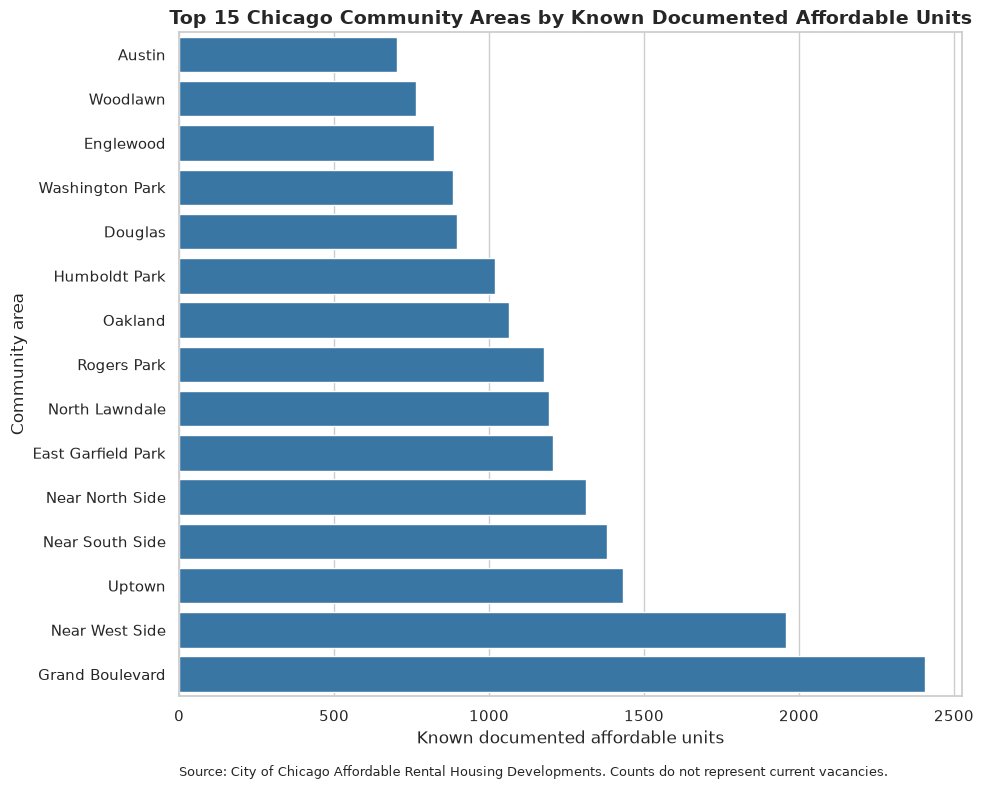

Figure saved to: /workspaces/chicago-homelessness-resource-allocation/chicago-homelessness-resource-allocation/reports/figures/top_community_areas_affordable_units.png


In [8]:
plot_data = (
    community_summary
    .dropna(
        subset=[
            "community_area",
            "documented_units_known",
        ]
    )
    .nlargest(
        15,
        "documented_units_known",
    )
    .sort_values(
        "documented_units_known",
        ascending=True,
    )
)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    data=plot_data,
    x="documented_units_known",
    y="community_area",
    color="#2878B5",
    ax=ax,
)

ax.set_title(
    "Top 15 Chicago Community Areas by Known Documented Affordable Units",
    fontsize=14,
    weight="bold",
)

ax.set_xlabel("Known documented affordable units")
ax.set_ylabel("Community area")

ax.text(
    0,
    -0.12,
    "Source: City of Chicago Affordable Rental Housing Developments. "
    "Counts do not represent current vacancies.",
    transform=ax.transAxes,
    fontsize=9,
)

plt.tight_layout()

figure_path = (
    project_root
    / "reports"
    / "figures"
    / "top_community_areas_affordable_units.png"
)

figure_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", figure_path)

In [9]:
community_output_path = (
    project_root
    / "data"
    / "processed"
    / "affordable_housing_by_community_area.csv"
)

property_type_output_path = (
    project_root
    / "data"
    / "processed"
    / "affordable_housing_by_property_type.csv"
)

community_summary.to_csv(
    community_output_path,
    index=False,
)

property_type_summary.to_csv(
    property_type_output_path,
    index=False,
)

saved_community_summary = pd.read_csv(
    community_output_path
)

saved_property_type_summary = pd.read_csv(
    property_type_output_path
)

assert saved_community_summary.shape == community_summary.shape
assert saved_property_type_summary.shape == property_type_summary.shape

print("Community summary:", community_output_path)
print("Property-type summary:", property_type_output_path)
print("All summary output checks passed.")

Community summary: /workspaces/chicago-homelessness-resource-allocation/chicago-homelessness-resource-allocation/data/processed/affordable_housing_by_community_area.csv
Property-type summary: /workspaces/chicago-homelessness-resource-allocation/chicago-homelessness-resource-allocation/data/processed/affordable_housing_by_property_type.csv
All summary output checks passed.


## Initial Observation

The community-area summary shows that affordable developments and known unit counts aren't evenly distributed across Chicago.

The community area with the highest known documented unit count in this dataset is **Grand Boulevard**, with **2,406** known units across **30** development records.

This shows where documented affordable housing supply is located in the City dataset. However, it does not mean that these units are currently vacant, accessible to everyone who needs housing, or enough to meet the housing needs in that area.